# Anexo A2. Búsqueda: más allá de BM25 y RRF

**Opcional** · **Dificultad: alta** · Complementa al notebook 4

1. TF-IDF con scikit-learn
2. La idf clásica de Robertson-Spärck Jones (ejercicio)
3. Combinación convexa frente a RRF
4. El mismo híbrido en una base de datos vectorial (Qdrant, en Docker)

Referencias:
- Fusión en recuperación híbrida (RRF y combinación convexa): https://arxiv.org/abs/2210.11934
- Consultas híbridas en Qdrant: https://qdrant.tech/documentation/concepts/hybrid-queries/

In [1]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/data/documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada


Trazas:      jsonl /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/trazas/trazas.jsonl  (alumno: profesor)


/home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/rag_lab/tracing.py:49: UserWarning: No se pudo conectar con Langfuse ([Errno 111] Connection refused): las trazas se guardan en JSONL.
  warnings.warn(f"No se pudo conectar con Langfuse ({e}): las trazas se guardan en JSONL.")


In [2]:
import numpy as np
import pandas as pd
from rag_lab import evaluation, results
from rag_lab.control_corpus import load_sqac

sqac = load_sqac()
ids = list(sqac["docs"])
texts = [sqac["docs"][i] for i in ids]
queries = sqac["consultas"]
print(f"{len(ids)} párrafos, {len(queries)} preguntas")
print("Ejemplo:", queries[0]["texto"], "->", sqac["docs"][queries[0]["doc"]][:200])

1249 párrafos, 200 preguntas
Ejemplo: ¿Cuántas viviendas han sido arrasadas en Nicaragua por el desastre? -> 14 de octubre de 2011 Varios fenómenos meteorológicos azotan a Centroamérica desde hace unos cinco días, generando miles de damnificados y decenas de muertos. Las comisiones respectivas de cada país h


In [3]:
def evaluate_searcher(search, k=10):
    """search(query, k) -> [(doc_id, puntuación)]. Cada documento cuenta como una 'página'."""
    rows = [{"recuperadas": [[d] for d, _ in search(q["texto"], k)], "correctas": [q["doc"]]} for q in queries]
    return evaluation.evaluate_retrieval(rows)

def register_control(version, technique, metrics):
    results.register({"version": version, "notebook": "A2", "tecnica": technique, "corpus": "sqac", **metrics})
    return metrics

## 1. TF-IDF con scikit-learn

Cada documento es un vector disperso con el peso TF-IDF de cada palabra; la consulta se compara por coseno.
scikit-learn no trae stopwords en español: usamos la lista de `bm25s`.

In [4]:
from bm25s.stopwords import STOPWORDS_SPANISH
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

tfidf = TfidfVectorizer(stop_words=list(STOPWORDS_SPANISH), sublinear_tf=True)
matrix = tfidf.fit_transform(texts)
print("Vocabulario:", len(tfidf.vocabulary_))

def search_tfidf(query, k=10):
    scores = linear_kernel(tfidf.transform([query]), matrix).ravel()
    order = np.argsort(-scores)[:k]
    return [(ids[i], float(scores[i])) for i in order]

register_control("S-tfidf", "TF-IDF (scikit-learn)", evaluate_searcher(search_tfidf))

Vocabulario: 29702


{'recall@5': 0.79, 'recall@10': 0.835, 'MRR@10': 0.717045634920635}

## 2. La idf de Robertson

El BM25 del notebook 4 (`ManualBM25`) usa la idf `log(1 + (N − df + 0,5) / (df + 0,5))`, que nunca es negativa.
La versión clásica no lleva el `1 +` y puede dar pesos negativos. Volvemos a definir `ManualBM25` para el ejercicio.

In [5]:
import math
import re
from collections import Counter, defaultdict

import Stemmer

stemmer = Stemmer.Stemmer("spanish")
stop = set(STOPWORDS_SPANISH)

def tokenize_es(text):
    return [stemmer.stemWord(w) for w in re.findall(r"\w\w+", text.lower()) if w not in stop]

class ManualBM25:
    def __init__(self, texts, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        tokens = [tokenize_es(t) for t in texts]
        self.lengths = np.array([len(t) for t in tokens])
        self.avg_len = self.lengths.mean()
        self.postings = defaultdict(list)  # término -> [(documento, tf)]
        for d, toks in enumerate(tokens):
            for term, tf in Counter(toks).items():
                self.postings[term].append((d, tf))
        n = len(texts)
        self.idf = {t: math.log(1 + (n - len(p) + 0.5) / (len(p) + 0.5)) for t, p in self.postings.items()}

    def score_docs(self, query):
        scores = np.zeros(len(self.lengths))
        for term in tokenize_es(query):
            for d, tf in self.postings.get(term, []):
                denom = self.k1 * (1 - self.b + self.b * self.lengths[d] / self.avg_len)
                scores[d] += self.idf[term] * tf * (self.k1 + 1) / (tf + denom)
        return scores

    def search(self, query, k=10):
        scores = self.score_docs(query)
        order = np.argsort(-scores)[:k]
        return [(ids[i], float(scores[i])) for i in order if scores[i] > 0]

manual_bm25 = ManualBM25(texts)
register_control("S-bm25-manual", "BM25 a mano (k1=1.5, b=0.75)", evaluate_searcher(manual_bm25.search))

{'recall@5': 0.775, 'recall@10': 0.84, 'MRR@10': 0.6694186507936507}

In [6]:
# TODO: la idf clásica de Robertson-Spärck Jones es log((N - df + 0.5) / (df + 0.5)) y puede ser negativa
# para términos que aparecen en más de la mitad de los documentos. Crea una subclase que la use y compara.
class RobertsonBM25(ManualBM25):
    def __init__(self, texts, k1=1.5, b=0.75):
        super().__init__(texts, k1, b)
        # Completa: recalcula self.idf con la fórmula de Robertson
        pass

print(evaluate_searcher(RobertsonBM25(texts).search))

{'recall@5': 0.775, 'recall@10': 0.84, 'MRR@10': 0.6694186507936507}


## 3. Combinación convexa frente a RRF

- **RRF** suma `1 / (k + posición)` de cada lista: solo usa posiciones, no hace falta normalizar puntuaciones.
- **Combinación convexa**: `α · denso + (1 − α) · BM25` con las puntuaciones normalizadas min-max. Hay que elegir α.

In [7]:
from rag_lab.indexes import BM25Index, DenseIndex

units = [{"id": i, "texto": t, "paginas": [i]} for i, t in zip(ids, texts)]
bm25s_idx = BM25Index(units, k1=1.5, b=0.75)
dense = DenseIndex("sqac", units, path=CFG.CACHE_DIR / "chroma_control")

In [8]:
def rrf_manual(rankings, k=60):
    scores = defaultdict(float)
    for ranking in rankings:
        for position_, (doc, _) in enumerate(ranking, start=1):
            scores[doc] += 1 / (k + position_)
    return sorted(scores.items(), key=lambda x: -x[1])

N = 50  # candidatos de cada lista
cand_bm25 = {q["id"]: bm25s_idx.search(q["texto"], N) for q in queries}
cand_dense = {q["id"]: dense.search(q["texto"], N) for q in queries}
text_to_id = {q["texto"]: q["id"] for q in queries}

def search_rrf(query, k=10):
    qid = text_to_id[query]
    return rrf_manual([cand_dense[qid], cand_bm25[qid]])[:k]

mrr_rrf = evaluate_searcher(search_rrf)["MRR@10"]
print("RRF (k=60): MRR@10 =", round(mrr_rrf, 3))

RRF (k=60): MRR@10 = 0.756


In [9]:
from rag_lab.retrieval import convex

rows = []
for alpha in np.round(np.arange(0, 1.01, 0.1), 1):
    def search_convex(query, k=10, alpha=alpha):
        qid = text_to_id[query]
        return convex(cand_dense[qid], cand_bm25[qid], alpha)[:k]
    rows.append({"alfa": alpha, **evaluate_searcher(search_convex)})
alpha_sweep = pd.DataFrame(rows).set_index("alfa")
best_alpha = float(alpha_sweep["MRR@10"].idxmax())
register_control("S-convexa", f"Combinación convexa (α={best_alpha})", alpha_sweep.loc[best_alpha].to_dict())
alpha_sweep[["recall@5", "recall@10", "MRR@10"]].round(3)

,recall@5,recall@10,MRR@10
alfa,,,
0.0,0.775,0.840,0.669
0.1,0.810,0.865,0.694
0.2,0.825,0.880,0.711
0.3,0.855,0.900,0.736
0.4,0.885,0.915,0.763
0.5,0.915,0.935,0.788
0.6,0.910,0.940,0.786
0.7,0.900,0.935,0.795
0.8,0.890,0.920,0.797


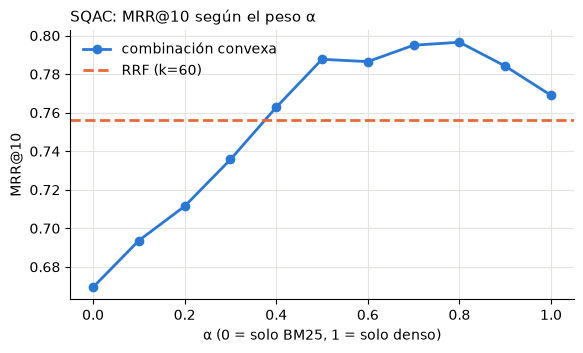

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(alpha_sweep.index, alpha_sweep["MRR@10"], color="#2a78d6", linewidth=2, marker="o", markersize=6,
        label="combinación convexa")
ax.axhline(mrr_rrf, color="#eb6834", linewidth=2, linestyle="--", label="RRF (k=60)")
ax.set_xlabel("α (0 = solo BM25, 1 = solo denso)")
ax.set_ylabel("MRR@10")
ax.set_title("SQAC: MRR@10 según el peso α", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## 4. El mismo híbrido en una base de datos vectorial

Hasta ahora el índice denso vive dentro del proceso de Python (Chroma, embebida). Una base de datos vectorial como servidor (Qdrant aquí, Elasticsearch en otra asignatura) guarda los vectores aparte y responde por API. Cada punto lleva un vector denso (BGE-M3), un vector disperso (los pesos BM25 de `bm25s`) y un *payload* con páginas, sección y tipo. La fusión RRF la hace el propio servidor.

Para levantarlo: `docker compose up -d` en `servidor/qdrant` (panel en http://localhost:6333/dashboard). Si no está en marcha, esta sección lo indica y no hace nada más.

Referencia: https://qdrant.tech/documentation/concepts/hybrid-queries/

In [11]:
from rag_lab import models, versions

questions = evaluation.load_questions()
from rag_lab.vector_db import QdrantHybrid, qdrant_available

qdrant_on = qdrant_available()
print("Qdrant disponible en", CFG.QDRANT_URL if qdrant_on else "(no responde): cd servidor/qdrant && docker compose up -d")

Qdrant disponible en (no responde): cd servidor/qdrant && docker compose up -d


In [12]:
if qdrant_on:
    v1_fragments = versions.pdf_fragments("cabeceras")
    qdrant_v1 = QdrantHybrid(v1_fragments, "rag-v1")
    print(qdrant_v1.count(), "puntos en la colección rag-v1")
    point = qdrant_v1.client.retrieve("rag-v1", ids=[0], with_vectors=True)[0]
    print("payload:", point.payload)
    print("vector denso:", len(point.vector["dense"]), "dimensiones | vector disperso:",
          len(point.vector["bm25"].indices), "términos con peso")

Comparamos con V3 hecho a mano (10 candidatos de cada lista y RRF con k = 60). Qdrant cuenta las posiciones desde 0, así que su `k = 61` equivale a nuestro `k = 60`; su valor por defecto es `k = 2`, que da mucho más peso a las primeras posiciones.

In [13]:
if qdrant_on:
    v3 = versions.build("V3")
    rows = []
    for q in questions:
        reference = [(u["id"], u["score"]) for u in v3.candidates(q["pregunta"])[:10]]
        server_60 = qdrant_v1.search(q["pregunta"], 10, rrf_k=61, candidates=10)
        server_2 = qdrant_v1.search(q["pregunta"], 10, rrf_k=None, candidates=10)
        ref_ids = [i for i, _ in reference]
        rows.append({
            "id": q["id"],
            "mismas puntuaciones (k=60)": sorted(round(s, 6) for _, s in reference) == sorted(round(s, 6) for _, s in server_60),
            "solapamiento top-10 (k=60)": len(set(ref_ids) & {i for i, _ in server_60}) / 10,
            "mismo orden (k=60)": ref_ids == [i for i, _ in server_60],
            "mismo orden (k=2, por defecto)": ref_ids == [i for i, _ in server_2],
        })
    comparison = pd.DataFrame(rows).set_index("id")
    display(comparison.mean().round(2).to_frame("proporción de preguntas"))

Con k = 60 las puntuaciones RRF coinciden; donde el orden no coincide es porque hay fragmentos empatados y cada implementación los desempata a su manera. Con el k por defecto el orden cambia.

El *payload* permite filtrar en la propia consulta, por ejemplo, solo fragmentos que son tablas:

In [14]:
if qdrant_on:
    query = "¿Qué porcentaje de participación tiene Dative en la fase 4?"
    by_id = {f["id"]: f for f in v1_fragments}
    for kind in [None, "tabla"]:
        hits = qdrant_v1.search(query, 3, kind=kind)
        print(f"filtro tipo={kind}:", [(i, by_id[i]["tipo"], by_id[i]["paginas"]) for i, _ in hits])

In [15]:
models.release()

## Qué hemos visto

- TF-IDF y BM25 son parientes: BM25 añade la saturación de la frecuencia y la normalización por longitud.
- La combinación convexa puede igualar o superar a RRF, pero hay que elegir α con datos y normalizar puntuaciones.
- Una base de datos vectorial como Qdrant hace la misma fusión en el servidor, con filtros por metadatos.